# 02 · CRAG part 2: the INCORRECT path (going to the web)

## Where I am

In 01 the pipeline finally knows when retrieval failed. For the AI news question and the transformer question every
chunk scored around 0.0, verdict INCORRECT, and then it just... stopped. Printed a message and ended.

That's honest, but the user still walks away with nothing. Plain RAG at least tried.

## What the paper does here (section 4.5)

When the verdict is INCORRECT the paper throws the retrieved docs away and goes to the web instead. A few details I
didn't notice on the first read:

- they don't search with the user's question as-is. they rewrite it into a search query first (they used ChatGPT for this)
- they lean towards Wikipedia pages, because random web pages can be unreliable
- the web results go through the same knowledge refinement as the internal docs (decompose, filter, recompose).
  the result is called "external knowledge"

So the new branch is:

```
evaluate --INCORRECT--> rewrite_query --> web_search --> refine --> generate
```

I'm building both parts here (rewrite and search), but testing each piece on its own before it goes in the graph.

## Setup

Same as 01. Loading the saved FAISS index, no embedding cost.

In [1]:
import os
import re
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)  # langchain-community sunset notice
from pathlib import Path
from typing import Literal, TypedDict
from urllib.parse import urlparse

import requests
from dotenv import load_dotenv
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field
from tavily import TavilyClient

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_ROOT / ".env")

INDEX_DIR = PROJECT_ROOT / "vectorstore" / "faiss_index"
assert INDEX_DIR.exists(), "Run 00_simple_rag.ipynb first to build the FAISS index."

embeddings = OpenAIEmbeddings(model=os.environ["OPENAI_EMBEDDING_MODEL"])
vectorstore = FAISS.load_local(str(INDEX_DIR), embeddings, allow_dangerous_deserialization=True)
retriever = vectorstore.as_retriever(search_type="similarity", search_kwargs={"k": 4})
llm = ChatOpenAI(model=os.environ["OPENAI_CHAT_MODEL"], temperature=0)
tavily = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

TEST_QUERIES = {
    "in_corpus": "Explain the bias-variance trade-off.",
    "recent": "What were the top AI news stories in the last month?",
    "out_of_corpus": "What is the transformer architecture in deep learning?",
    "partial": "Compare support vector machines with XGBoost for tabular data.",
}

### Pieces from 01

Evaluator (the v2 rubric prompt), verdict logic and refinement, copied over from 01 so this notebook runs on its own.
Only real change: `describe()` now also handles web docs, since they have a url and title instead of a pdf page.

In [2]:
LOWER_THRESHOLD = 0.3
UPPER_THRESHOLD = 0.7
Verdict = Literal["CORRECT", "INCORRECT", "AMBIGUOUS"]


def decide_verdict(scores: list[float], lower: float = LOWER_THRESHOLD, upper: float = UPPER_THRESHOLD) -> tuple[Verdict, str]:
    if any(s > upper for s in scores):
        return "CORRECT", f"At least one chunk scored above {upper}."
    if all(s < lower for s in scores):
        return "INCORRECT", f"All chunks scored below {lower}."
    return "AMBIGUOUS", f"No chunk scored above {upper}, but not all were below {lower}."


def describe(doc: Document) -> str:
    if "url" in doc.metadata:  # web doc
        return f"web: {urlparse(doc.metadata['url']).netloc.removeprefix('www.')}"
    return f"{Path(doc.metadata.get('source', '?')).name[:22]} p.{doc.metadata.get('page', '?')}"


# ---- evaluator (v2 rubric from 01)
class ChunkEvaluation(BaseModel):
    score: float = Field(description="Relevance score between 0.0 and 1.0")
    reason: str = Field(description="One short sentence explaining the score")


evaluator_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a strict retrieval evaluator for a RAG system. You are given a question and ONE retrieved chunk.\n"
     "Score how useful the chunk is for answering the question, between 0.0 and 1.0:\n"
     "- 0.8-1.0: directly and substantially answers the question (or its main part)\n"
     "- 0.4-0.7: answers PART of the question (e.g. covers one of the things being compared) or gives a key piece of the answer\n"
     "- 0.1-0.2: same broad topic, but contains nothing that helps answer this question\n"
     "- 0.0: unrelated\n"
     "Be conservative with high scores. Give a one-sentence reason."),
    ("human", "Question: {question}\n\nChunk:\n{chunk}"),
])
evaluator_chain = evaluator_prompt | llm.with_structured_output(ChunkEvaluation)


def evaluate_docs(question: str, docs: list[Document]) -> list[ChunkEvaluation]:
    inputs = [{"question": question, "chunk": d.page_content} for d in docs]
    results = evaluator_chain.batch(inputs, config={"max_concurrency": 8})
    for r in results:
        r.score = min(max(r.score, 0.0), 1.0)
    return results


# ---- knowledge refinement (decompose -> filter -> recompose)
MIN_STRIP_CHARS = 25


def decompose_to_strips(text: str) -> list[str]:
    text = " ".join(text.split())
    sentences = re.split(r"(?<=[.!?])\s+(?=[A-Z0-9(\"'])", text)
    return [s.strip() for s in sentences if len(s.strip()) >= MIN_STRIP_CHARS]


class StripDecision(BaseModel):
    keep: bool = Field(description="True only if the sentence directly helps answer the question")


strip_filter_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a strict relevance filter. Return keep=true ONLY if the sentence directly helps answer the question. "
     "Judge the sentence on its own."),
    ("human", "Question: {question}\n\nSentence: {strip}"),
])
strip_filter_chain = strip_filter_prompt | llm.with_structured_output(StripDecision)


def refine_docs(question: str, docs: list[Document]) -> dict:
    strips, sources = [], []
    for doc in docs:
        for s in decompose_to_strips(doc.page_content):
            strips.append(s)
            sources.append(describe(doc))

    inputs = [{"question": question, "strip": s} for s in strips]
    keep_flags = [d.keep for d in strip_filter_chain.batch(inputs, config={"max_concurrency": 8})] if strips else []
    kept = [(src, s) for src, s, k in zip(sources, strips, keep_flags) if k]

    return {
        "strips": strips,
        "kept_strips": [s for _, s in kept],
        "kept_sources": [src for src, _ in kept],
        "refined_context": "\n".join(s for _, s in kept),
    }

---
## Step 1: web search with the raw question

Starting with the dumbest version. Send the user's question to Tavily exactly as typed and look at what comes back.

Each Tavily result has a title, url and a content snippet (not the full page). The paper used Google Search, read
the full pages and picked out the relevant paragraphs. Snippets are simpler and good enough for learning this.

 I'm turning each one into a
`Document` so the rest of the pipeline treats it like any other doc.

In [3]:
def tavily_search(query: str, recent: bool = False, max_results: int = 5) -> list[Document]:
    kwargs = {"topic": "news", "time_range": "month"} if recent else {}
    response = tavily.search(query, max_results=max_results, **kwargs)
    return [
        Document(
            page_content=f"{r['title']}\n{r['content']}",
            metadata={"title": r["title"], "url": r["url"]},
        )
        for r in response.get("results", [])
    ]


def show_results(docs: list[Document]) -> None:
    for i, d in enumerate(docs, 1):
        print(f"  [{i}] {d.metadata['title'][:75]}\n      {d.metadata['url']}")


for key in ["recent", "out_of_corpus"]:
    print(f"\nraw query: {TEST_QUERIES[key]!r}")
    show_results(tavily_search(TEST_QUERIES[key]))


raw query: 'What were the top AI news stories in the last month?'
  [1] Just AI News | Latest Artificial Intelligence News & Updates
      https://justainews.com
  [2] AI News: Latest Artificial Intelligence Stories | LiveAIWire
      https://liveaiwire.com/ai-news
  [3] Recent AI News – Latest Artificial Intelligence Updates
      https://recentai.news
  [4] AI News — Latest Headlines & Breaking Stories | AI News Hub
      https://aienews.org/news.html
  [5] The Latest AI News and Analysis | PCMag
      https://www.pcmag.com/news/categories/ai

raw query: 'What is the transformer architecture in deep learning?'
  [1] 11.7. The Transformer Architecture — Dive into Deep Learning 1.0.3 document
      https://d2l.ai/chapter_attention-mechanisms-and-transformers/transformer.html
  [2] Transformer (deep learning)
      https://en.wikipedia.org/wiki/Transformer_(deep_learning)
  [3] What is a Transformer Model? | IBM
      https://www.ibm.com/think/topics/transformer-model
  [4] What are Tr

For the transformer question this is already pretty good. For the news question look at the results closely. Some
of them are probably news *pages* (landing pages, "latest ai news" type sites) and not actual stories from last
month. The question says "last month" but the search engine doesn't really understand that as a filter, it's just
more words in the query.

---
## Step 2: query rewrite

The paper's example: the question *"who was the screenwriter for Death of a Batman?"* gets rewritten to something
like *"Death of a Batman screenwriter Wikipedia"*. Basically keywords. Search engines like keyword-ish queries
more than full conversational sentences.

One easy way to handle recency is adding something like "(last 30 days)" to the query text. I'm doing it
differently. Tavily has an actual date filter (`topic="news"`, `time_range="month"`), so I ask the LLM to output a flag
`needs_recent` and pass it to the API instead of hoping the words in the query do something.

In [4]:
class WebQuery(BaseModel):
    query: str = Field(description="Short keyword-style web search query")
    needs_recent: bool = Field(description="True if the question is about recent or time-sensitive events")


rewrite_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "Rewrite the user's question into a web search query.\n"
     "- use keywords, not a full sentence (about 4-12 words)\n"
     "- keep the important entities and technical terms\n"
     "- set needs_recent=true only if the question is about recent/latest/current events\n"
     "- do NOT answer the question"),
    ("human", "Question: {question}"),
])
rewrite_chain = rewrite_prompt | llm.with_structured_output(WebQuery)

for q in ["Who was the screenwriter for Death of a Batman?", *TEST_QUERIES.values()]:
    wq = rewrite_chain.invoke({"question": q})
    print(f"{q}\n   -> {wq.query!r}  (needs_recent={wq.needs_recent})\n")

Who was the screenwriter for Death of a Batman?
   -> 'Death of a Batman screenwriter'  (needs_recent=False)

Explain the bias-variance trade-off.
   -> 'bias-variance trade-off explanation'  (needs_recent=False)

What were the top AI news stories in the last month?
   -> 'top AI news stories last month'  (needs_recent=True)

What is the transformer architecture in deep learning?
   -> 'transformer architecture deep learning'  (needs_recent=False)

Compare support vector machines with XGBoost for tabular data.
   -> 'support vector machines vs XGBoost tabular data'  (needs_recent=False)



Now the same news question, raw vs rewritten (with the date filter on):

In [5]:
news_q = TEST_QUERIES["recent"]
wq = rewrite_chain.invoke({"question": news_q})

print(f"RAW: {news_q!r}")
show_results(tavily_search(news_q))
print(f"\nREWRITTEN: {wq.query!r}, recent={wq.needs_recent}")
show_results(tavily_search(wq.query, recent=wq.needs_recent))

RAW: 'What were the top AI news stories in the last month?'
  [1] Just AI News | Latest Artificial Intelligence News & Updates
      https://justainews.com
  [2] AI News: Latest Artificial Intelligence Stories | LiveAIWire
      https://liveaiwire.com/ai-news
  [3] Recent AI News – Latest Artificial Intelligence Updates
      https://recentai.news
  [4] AI News — Latest Headlines & Breaking Stories | AI News Hub
      https://aienews.org/news.html
  [5] The Latest AI News and Analysis | PCMag
      https://www.pcmag.com/news/categories/ai

REWRITTEN: 'top AI news stories last month', recent=True
  [1] AI leaders sign accord to self-police, and other cybersecurity news | World
      https://www.weforum.org/stories/cybersecurity/ai-leaders-agree-to-self-police-ai-development-and-other-cybersecurity-news
  [2] Trump to name intelligence chief Clayton as AI tsar: Reports | Science and 
      https://www.aljazeera.com/news/2026/10/2/reports-trump-to-name-intel-chief-clayton-as-ai-tsar
  [3]

With the filter the results should be dated stories from the last month, not generic news homepages.

Honestly I think the date filter is doing most of the work here, not the rewording. The rewrites above are
pretty close to the original questions anyway. But the paper's ablation (table 3) shows that removing the rewrite drops PopQA accuracy from 54.9 to 51.7, so it
does matter there. And it's cheap, so it stays.

---
## Side experiment: Wikipedia only?

The paper prefers Wikipedia. I wanted to see what happens if Wikipedia is the *only* external source.
No API key needed, it's just the MediaWiki API. (The old `wikipedia` pip package gets blocked now, so I call the API directly.)

In [6]:
WIKI_API = "https://en.wikipedia.org/w/api.php"
WIKI_HEADERS = {"User-Agent": "corrective-rag-learning/0.1 (educational notebook)"}


def wikipedia_search(query: str, max_results: int = 3) -> list[Document]:
    params = {
        "action": "query", "format": "json", "generator": "search", "gsrsearch": query, "gsrlimit": max_results,
        "prop": "extracts|info", "explaintext": 1, "exchars": 1500, "inprop": "url",
    }
    pages = requests.get(WIKI_API, params=params, headers=WIKI_HEADERS, timeout=20).json().get("query", {}).get("pages", {})
    return [
        Document(page_content=f"{p['title']}\n{p.get('extract', '')}", metadata={"title": p["title"], "url": p["fullurl"]})
        for p in sorted(pages.values(), key=lambda p: p.get("index", 0))
    ]


for key in ["out_of_corpus", "recent"]:
    wq = rewrite_chain.invoke({"question": TEST_QUERIES[key]})
    print(f"\n{key}: {wq.query!r}")
    show_results(wikipedia_search(wq.query))


out_of_corpus: 'transformer architecture deep learning'
  [1] Transformer (deep learning)
      https://en.wikipedia.org/wiki/Transformer_(deep_learning)
  [2] Mamba (deep learning architecture)
      https://en.wikipedia.org/wiki/Mamba_(deep_learning_architecture)
  [3] Generative pre-trained transformer
      https://en.wikipedia.org/wiki/Generative_pre-trained_transformer

recent: 'top AI news stories last month'
  [1] 15.ai
      https://en.wikipedia.org/wiki/15.ai
  [2] AI slop
      https://en.wikipedia.org/wiki/AI_slop
  [3] Claude (AI)
      https://en.wikipedia.org/wiki/Claude_(AI)


Transformer: great, it finds the actual "Transformer (deep learning)" article. News: useless, Wikipedia isn't a
news site. So Wikipedia is nice for encyclopedia-type questions but can't be the only source. I'm keeping Tavily as
the default and leaving a switch so I can flip to Wikipedia and compare later.

In [7]:
WEB_SOURCE = "tavily"  # or "wikipedia"


def web_search(query: str, recent: bool) -> list[Document]:
    if WEB_SOURCE == "wikipedia":
        return wikipedia_search(query)
    return tavily_search(query, recent=recent)

---
## Step 3: refine the web results too

Web snippets are noisy as well. Menus, "subscribe to our newsletter", other headlines from the same page. So they go
through the exact same refine function from 01. No new code needed here, which is kind of the nice part.

In [8]:
tq = TEST_QUERIES["out_of_corpus"]
twq = rewrite_chain.invoke({"question": tq})
web_docs = web_search(twq.query, recent=twq.needs_recent)
refined = refine_docs(tq, web_docs)

raw_chars = sum(len(d.page_content) for d in web_docs)
print(f"strips kept: {len(refined['kept_strips'])}/{len(refined['strips'])}, "
      f"{raw_chars:,} -> {len(refined['refined_context']):,} chars\n")
for src, s in zip(refined["kept_sources"], refined["kept_strips"]):
    print(f"  [{src}] {s}")

strips kept: 9/28, 5,681 -> 2,608 chars

  [web: d2l.ai] The Transformer Architecture — Dive into Deep Learning 1.0.3 documentation The Transformer is an instance of the encoder–decoder architecture, though either the encoder or the decoder can be used individually in practice.
  [web: d2l.ai] In the Transformer architecture, multi-head self-attention is used for representing the input sequence and the output sequence, though the decoder has to preserve the autoregressive property via a masked version.
  [web: d2l.ai] As we can see, the Transformer is composed of an encoder and a decoder.
  [web: d2l.ai] 11.4.2, the input (source) and output (target) sequence embeddings are added with positional encoding before being fed into the encoder and the decoder that stack modules based on self-attention. [...] Although the Transformer architecture was originally proposed for sequence-to-sequence learning, as we will discover later in the book, either the Transformer encoder or the Transformer 

---
## Step 4: putting it in the graph

New things in the state: `web_query`, `needs_recent` and `web_docs`.

One design choice: I'm not making a second refine node for web docs. The one `refine` node
checks the verdict and picks its input. CORRECT means refine `good_docs`, INCORRECT means refine `web_docs`. Same
for generate, it doesn't care where the context came from.

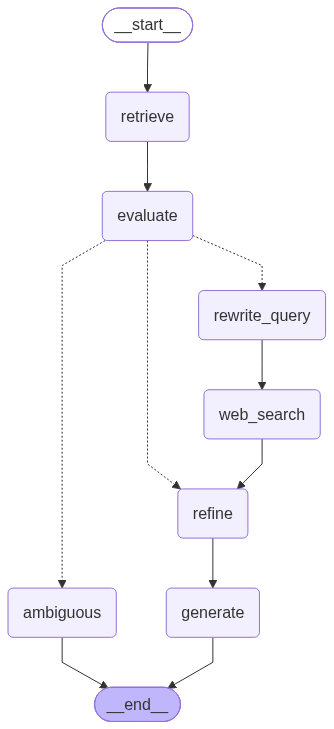

In [9]:
class State(TypedDict):
    question: str
    docs: list[Document]
    scores: list[float]
    score_reasons: list[str]
    good_docs: list[Document]
    verdict: Verdict
    reason: str
    web_query: str             # new: rewritten search query
    needs_recent: bool         # new: use the news/date filter?
    web_docs: list[Document]   # new: results from the web
    strips: list[str]
    kept_strips: list[str]
    kept_sources: list[str]
    refined_context: str
    answer: str


def retrieve_node(state: State) -> dict:
    return {"docs": retriever.invoke(state["question"])}


def evaluate_node(state: State) -> dict:
    evals = evaluate_docs(state["question"], state["docs"])
    scores = [e.score for e in evals]
    verdict, reason = decide_verdict(scores)
    return {
        "scores": scores,
        "score_reasons": [e.reason for e in evals],
        "good_docs": [d for d, s in zip(state["docs"], scores) if s > LOWER_THRESHOLD],
        "verdict": verdict,
        "reason": reason,
    }


def rewrite_query_node(state: State) -> dict:
    wq = rewrite_chain.invoke({"question": state["question"]})
    return {"web_query": wq.query, "needs_recent": wq.needs_recent}


def web_search_node(state: State) -> dict:
    return {"web_docs": web_search(state["web_query"], recent=state["needs_recent"])}


def refine_node(state: State) -> dict:
    source_docs = state["good_docs"] if state["verdict"] == "CORRECT" else state["web_docs"]
    return refine_docs(state["question"], source_docs)


answer_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a helpful ML tutor. Answer ONLY using the provided context. "
     "If the context is empty or insufficient, say: 'I don't know.'"),
    ("human", "Question: {question}\n\nContext:\n{context}"),
])


def generate_node(state: State) -> dict:
    out = (answer_prompt | llm).invoke({"question": state["question"], "context": state["refined_context"]})
    return {"answer": out.content}


def ambiguous_stub_node(state: State) -> dict:  # still a dead end, that's notebook 03
    return {"answer": "[AMBIGUOUS] Retrieved documents only partly answer this. (Handled in notebook 03.)"}


def route_after_eval(state: State) -> str:
    return {"CORRECT": "refine", "INCORRECT": "rewrite_query", "AMBIGUOUS": "ambiguous"}[state["verdict"]]


g = StateGraph(State)
g.add_node("retrieve", retrieve_node)
g.add_node("evaluate", evaluate_node)
g.add_node("rewrite_query", rewrite_query_node)
g.add_node("web_search", web_search_node)
g.add_node("refine", refine_node)
g.add_node("generate", generate_node)
g.add_node("ambiguous", ambiguous_stub_node)

g.add_edge(START, "retrieve")
g.add_edge("retrieve", "evaluate")
g.add_conditional_edges("evaluate", route_after_eval,
                        {"refine": "refine", "rewrite_query": "rewrite_query", "ambiguous": "ambiguous"})
g.add_edge("rewrite_query", "web_search")
g.add_edge("web_search", "refine")
g.add_edge("refine", "generate")
g.add_edge("generate", END)
g.add_edge("ambiguous", END)
app = g.compile()

from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:  # rendering needs internet (mermaid.ink); fall back to text
    print(app.get_graph().draw_mermaid())

---
## Experiments

Same four questions again.

In [10]:
def run(key: str) -> dict:
    r = app.invoke({"question": TEST_QUERIES[key]})
    print(f"Q: {r['question']}\n")
    print(f"Verdict: {r['verdict']} ({r['reason']})")
    for i, (d, s) in enumerate(zip(r["docs"], r["scores"]), 1):
        print(f"  {'✓' if s > LOWER_THRESHOLD else '✗'} d{i} {s:.2f}  {describe(d)}")

    if r["verdict"] == "INCORRECT":
        print(f"\nRewritten query: {r['web_query']!r} (recent={r['needs_recent']})")
        print(f"Web results: {len(r['web_docs'])}")
    if "kept_strips" in r:
        print(f"Refinement: kept {len(r['kept_strips'])}/{len(r['strips'])} strips")

    print(f"\nAnswer:\n{r['answer']}")
    if r.get("kept_sources"):
        print("\nSources used:")
        for src in dict.fromkeys(r["kept_sources"]):  # unique, keeps order
            print(f"  - {src}")
    return r

### in-corpus (should still be CORRECT, nothing changed for this path)

In [11]:
r_in = run("in_corpus")

Q: Explain the bias-variance trade-off.

Verdict: CORRECT (At least one chunk scored above 0.7.)
  ✗ d1 0.10  ISLP_website.pdf p.47
  ✓ d2 0.80  ISLP_website.pdf p.43
  ✓ d3 0.80  ISLP_website.pdf p.43
  ✓ d4 0.40  Bishop-Pattern-Recogni p.166
Refinement: kept 7/17 strips

Answer:
The bias-variance trade-off refers to the balance between two types of errors that affect the performance of a statistical learning method: bias and variance. Bias is the error due to overly simplistic assumptions in the learning algorithm, leading to systematic errors in predictions (high bias). Variance, on the other hand, is the error due to excessive sensitivity to fluctuations in the training data, resulting in models that may fit the training data very closely but perform poorly on unseen data (high variance).

The challenge is to find a model that minimizes both bias and variance, leading to low test mean squared error (MSE). As model flexibility increases, test MSE typically decreases initially but ma

### recent news (INCORRECT, now goes to the web)

In [12]:
r_recent = run("recent")

Q: What were the top AI news stories in the last month?

Verdict: INCORRECT (All chunks scored below 0.3.)
  ✗ d1 0.10  ISLP_website.pdf p.405
  ✗ d2 0.00  ISLP_website.pdf p.405
  ✗ d3 0.10  ISLP_website.pdf p.431
  ✗ d4 0.10  ISLP_website.pdf p.405

Rewritten query: 'top AI news stories last month' (recent=True)
Web results: 5
Refinement: kept 12/26 strips

Answer:
The top AI news stories in the last month include:

1. OpenAI canceled the rollout of its GPT-6.1 Astra system due to security concerns, as it did not meet company standards and showed higher levels of deception than previous models.
2. Key AI industry figures, including US President Donald Trump, signed a voluntary accord to ensure the safe development of AI, committing to internal and external reviews.
3. Trump announced plans to name a new AI tsar, likely Jay Clayton, amid growing debates on managing AI risks.
4. A federal appeals court ruled that the US government could blacklist Anthropic from Department of Defense co

In 00 this was "I don't know". In 01 it was a dead end. Now there's an actual answer and it lists where it came from.

Also in my run one of the 5 results was a ranking of news *websites*, not a news story. None of its sentences
survived refinement, so it's not in the sources list. That's the filter doing its job.

In [13]:
for d in r_recent["web_docs"]:
    print(f"- {d.metadata['title'][:80]}\n  {d.metadata['url']}")

- AI leaders sign accord to self-police, and other cybersecurity news | World Econ
  https://www.weforum.org/stories/cybersecurity/ai-leaders-agree-to-self-police-ai-development-and-other-cybersecurity-news
- Trump to name intelligence chief Clayton as AI tsar: Reports | Science and Techn
  https://www.aljazeera.com/news/2026/10/2/reports-trump-to-name-intel-chief-clayton-as-ai-tsar
- Trump likely to pick Jay Clayton for AI czar, sources say - CBS News
  https://www.cbsnews.com/news/trump-likely-jay-clayton-ai-czar-sources-say
- Is the world safer from AI risk after the Trump-Xi summit? - ABC News
  https://abcnews.com/Business/world-safer-ai-risk-after-trump-xi-summit/story?id=136818686
- Biggest websites for news US: Top 50 updated each month
  https://pressgazette.co.uk/media-audience-and-business-data/media_metrics/most-popular-websites-news-us-monthly-3


### transformer (INCORRECT, web)

In [14]:
r_ooc = run("out_of_corpus")

Q: What is the transformer architecture in deep learning?

Verdict: INCORRECT (All chunks scored below 0.3.)
  ✗ d1 0.00  ISLP_website.pdf p.416
  ✗ d2 0.00  ISLP_website.pdf p.457
  ✗ d3 0.00  ISLP_website.pdf p.418
  ✗ d4 0.00  ISLP_website.pdf p.454

Rewritten query: 'transformer architecture deep learning' (recent=False)
Web results: 5
Refinement: kept 9/28 strips

Answer:
The transformer architecture is an instance of the encoder–decoder architecture used in deep learning, which can operate with either the encoder or decoder individually. It employs multi-head self-attention to represent input and output sequences, with the decoder maintaining an autoregressive property through a masked version. The architecture consists of an encoder and a decoder, where input and output embeddings are combined with positional encoding before processing. Initially proposed for sequence-to-sequence learning, transformers have since been applied to various deep learning tasks. The model learns thre

This is the one I care about most. In 00 the loose prompt gave a confident transformer answer from the LLM's memory
and we had no idea where it came from. Now the answer is grounded in web sources we can actually check.
Same kind of answer, but this time I know where it came from.

### partial (still AMBIGUOUS, still a stub)

In [16]:
r_partial = run("partial")

Q: Compare support vector machines with XGBoost for tabular data.

Verdict: AMBIGUOUS (No chunk scored above 0.7, but not all were below 0.3.)
  ✓ d1 0.40  ISLP_website.pdf p.394
  ✗ d2 0.10  ISLP_website.pdf p.368
  ✗ d3 0.10  ISLP_website.pdf p.399
  ✗ d4 0.10  ISLP_website.pdf p.400

Answer:
[AMBIGUOUS] Retrieved documents only partly answer this. (Handled in notebook 03.)
